<a href="https://colab.research.google.com/github/kuroshkarimi/Machine-Learning-and-Data-Analysis/blob/main/Classic_Machine_Learning/Probability_Calibration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Probability Calibration

Create a dataset with 20-000 total sample; out of these samples, 40% should be positive and the rest negative. Then train a small neural network, inspect its scores, and check if the probabilities are calibrated.

For generation of the data use 'make_classification()' function from sickit learn data package with the following characteristics:

| Parameter | Definition|
|---|---|
| `n_samples=20_000` | Generate 20,000 observations. The underscore makes the number easier to read; `20_000` equals `20000`. |
| `n_features=20` | Give each observation 20 numerical features. |
| `n_informative=10` | Use 10 original features to construct patterns that distinguish the classes. |
| `n_redundant=5` | Add 5 features created as random linear combinations of the informative features. |
| `weights=[0.98, 0.02]` | Assign 98% of samples to class `0` and 2% to class `1`. |
| `flip_y=0` | Disable random reassignment of class labels. |
| `random_state=42` | Fix the random seed so the same call is reproducible in the same software environment. |




In [46]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

SEED = 42

# 1. Generate features and actual labels.
x, y = make_classification(
    n_samples=20_000,
    n_features=20,
    n_informative=10,
    n_redundant=5,
    weights=[0.6, 0.4],
    flip_y=0,
    random_state=SEED
)

# 2. Reserve 20% for final evaluation.
x_remaining, x_test, y_remaining, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    stratify=y,
    random_state=SEED
)

# 3. Split the remainder into training and calibration data.
# Overall: 60% training, 20% calibration, 20% testing.
x_train, x_cal, y_train, y_cal = train_test_split(
    x_remaining,
    y_remaining,
    test_size=0.25,
    stratify=y_remaining,
    random_state=SEED
)

# 4. Train a model without applying probability calibration.
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(
    max_depth=5,
    random_state=SEED
)

model.fit(x_train, y_train)

p_cal_uncalibrated = model.predict_proba(x_cal)[:, 1]
p_test_uncalibrated = model.predict_proba(x_test)[:, 1]

          bin  count  positives  mean_probability  positive_fraction       gap                 assessment
(-0.001, 0.1]   1330         66          0.029100           0.049624 -0.020524 Within 5 percentage points
   (0.1, 0.2]    400         55          0.129845           0.137500 -0.007655 Within 5 percentage points
   (0.2, 0.3]    629        156          0.239035           0.248013 -0.008978 Within 5 percentage points
   (0.3, 0.4]      9          3          0.322581           0.333333 -0.010753 Within 5 percentage points
   (0.5, 0.6]     10          8          0.577409           0.800000 -0.222591             Underestimated
   (0.6, 0.7]    105         67          0.659860           0.638095  0.021765 Within 5 percentage points
   (0.7, 0.8]    642        440          0.710754           0.685358  0.025396 Within 5 percentage points
   (0.8, 0.9]     20         16          0.866213           0.800000  0.066213              Overestimated
   (0.9, 1.0]    855        789          0.934

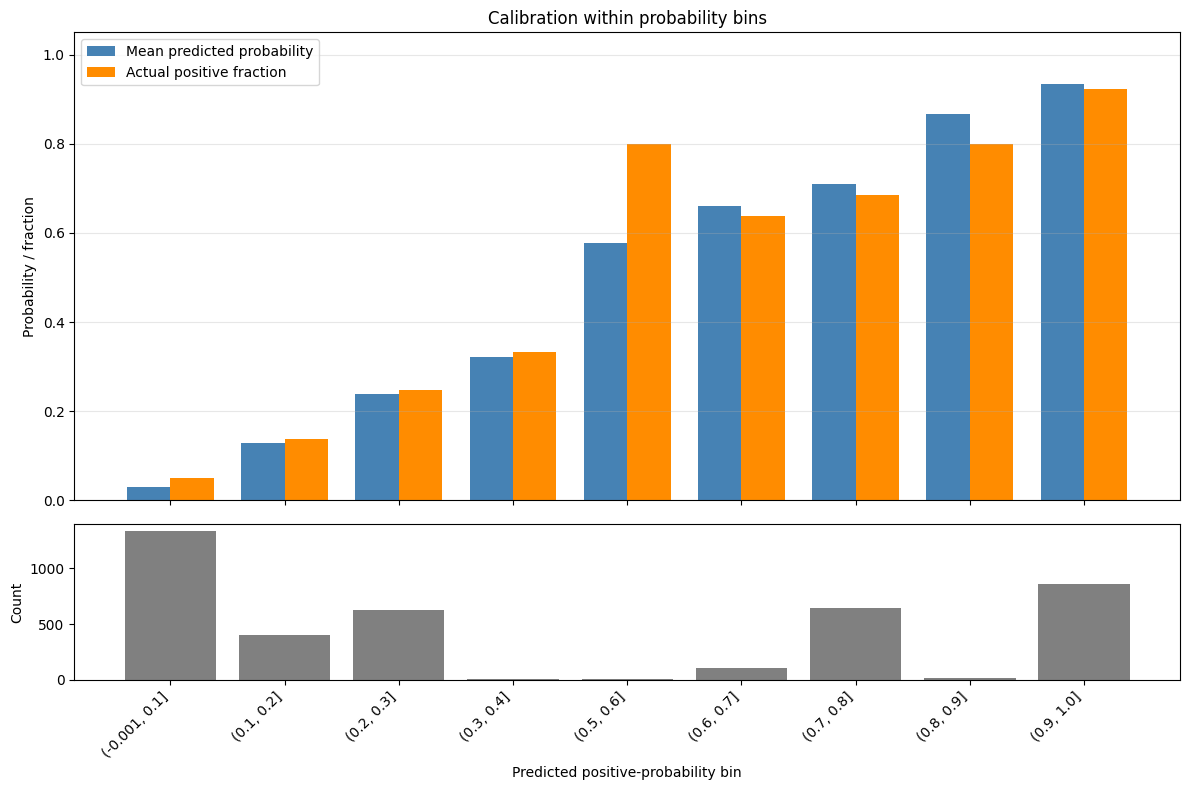

In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Actual labels: 0 = negative, 1 = positive
# Scores: predicted probability of the POSITIVE class
y_true = np.asarray(y_test).ravel()
probabilities = np.asarray(p_test_uncalibrated).ravel()

data = pd.DataFrame({
    "actual": y_true,
    "probability": probabilities,
})

# Ten equal-width bins: [0, 0.1], (0.1, 0.2], ..., (0.9, 1.0]
bin_edges = np.linspace(0, 1, 11)

data["bin"] = pd.cut(
    data["probability"],
    bins=bin_edges,
    include_lowest=True,
)

summary = (
    data.groupby("bin", observed=False)
    .agg(
        count=("actual", "size"),
        positives=("actual", "sum"),
        mean_probability=("probability", "mean"),
        positive_fraction=("actual", "mean"),
    )
    .reset_index()
)

# Empty bins cannot be assessed.
summary = summary.loc[summary["count"] > 0].copy()

# Positive gap: estimated positive probability is too high.
summary["gap"] = (
    summary["mean_probability"]
    - summary["positive_fraction"]
)

# A descriptive tolerance, not a statistical significance test.
tolerance = 0.05

summary["assessment"] = np.select(
    [
        summary["gap"] > tolerance,
        summary["gap"] < -tolerance,
    ],
    [
        "Overestimated",
        "Underestimated",
    ],
    default="Within 5 percentage points",
)

print(summary.to_string(index=False))

positions = np.arange(len(summary))
width = 0.38

fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 8),
    sharex=True,
    gridspec_kw={"height_ratios": [3, 1]},
)

axes[0].bar(
    positions - width / 2,
    summary["mean_probability"],
    width,
    label="Mean predicted probability",
    color="steelblue",
)

axes[0].bar(
    positions + width / 2,
    summary["positive_fraction"],
    width,
    label="Actual positive fraction",
    color="darkorange",
)

axes[0].set_ylabel("Probability / fraction")
axes[0].set_ylim(0, 1.05)
axes[0].set_title("Calibration within probability bins")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(
    positions,
    summary["count"],
    color="gray",
)

axes[1].set_ylabel("Count")
axes[1].set_xlabel("Predicted positive-probability bin")
axes[1].set_xticks(positions)
axes[1].set_xticklabels(
    summary["bin"].astype(str),
    rotation=45,
    ha="right",
)

plt.tight_layout()
plt.show()

In [1]:
# Importing required libraries
from sklearn.datasets import make_classification
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from keras.models import Sequential
from keras.layers import Dense, Input, Activation, Dropout, BatchNormalization
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,

    )

from keras.optimizers import Adam
from keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

In [2]:
# Fix the random seeds

SEED = 42
tf.keras.utils.set_random_seed(SEED)

In [27]:
# Creating the data as required

n_feature = 20
x, y = make_classification(
    n_samples = 20_000,
    n_features = n_feature,
    n_informative = 10,
    n_redundant = 5,
    weights = [0.6, 0.4],
    flip_y = 0,
    random_state = SEED
)

print(y)

[1 0 1 ... 1 0 1]


In [28]:
# Splitting the data into training, validation and test sets

x_tr_val, x_test, y_tr_val, y_test = train_test_split(
                        x, y, test_size = 0.2,
                        stratify = y, random_state = SEED)


x_train, x_val, y_train, y_val = train_test_split(
                        x_tr_val, y_tr_val, test_size = 0.25,
                        stratify = y_tr_val, random_state = SEED)

In [29]:
# Now we see if the population of the positives is 2% across all parts

print(np.mean(y_train), np.mean(y_val), np.mean(y_test))

0.4 0.4 0.4


In [30]:
# Scaling the data through the scaling parameters attained from the training set

scaler = StandardScaler()
scaler.fit_transform(x_train)
x_train = scaler.transform(x_train)
x_val = scaler.transform(x_val)
x_test = scaler.transform(x_test)

In [31]:
# Creating the architecture of the model

model = Sequential([
    Input(shape = (n_feature,)),

    Dense(100, activation = 'relu', kernel_initializer = 'he_normal'),
    BatchNormalization(),
    Dropout(0.2),

    Dense(50, activation = 'relu', kernel_initializer = 'he_normal'),
    BatchNormalization(),
    Dropout(0.2),

    Dense(25, activation = 'relu', kernel_initializer = 'he_normal'),
    BatchNormalization(),
    Dropout(0.2),

    Dense(1, activation = 'sigmoid')

]
)



In [32]:
# Compiling the model

model.compile(
    optimizer = Adam(learning_rate = 0.0001),
    loss = 'binary_crossentropy'
)


In [33]:

# Early stopping criteria
early_stopping = EarlyStopping(
    monitor = 'val_loss',
    patience = 10,
    restore_best_weights = True,
    verbose = 1,
    mode = 'min',
    min_delta = 0,

    )


# Model to be saved
model_checkpoint = ModelCheckpoint(
    'model.keras',
    monitor = 'val_loss',
    mode = 'min',
    save_best_only = True,
    verbose = 1
)


# Adjusting the learning rate
lr_reduce = ReduceLROnPlateau(
    monitor = 'val_loss',
    factor = 0.1,
    patience = 5,
    verbose = 1,
    mode = 'min',
    min_delta = 0
)





In [34]:
# Fitting the model

HIST = model.fit(x_train, y_train,
          validation_data = (x_val, y_val),
          epochs = 200,
          callbacks = [early_stopping, model_checkpoint, lr_reduce],
          verbose = 1,
          batch_size = 200,
          shuffle = True,

)

Epoch 1/200
52/60 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.8671
Epoch 1: val_loss improved from None to 0.67807, saving model to model.keras

Epoch 1: finished saving model to model.keras
60/60 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 0.8271 - val_loss: 0.6781 - learning_rate: 1.0000e-04
Epoch 2/200
58/60 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.7326
Epoch 2: val_loss improved from 0.67807 to 0.57276, saving model to model.keras

Epoch 2: finished saving model to model.keras
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.7065 - val_loss: 0.5728 - learning_rate: 1.0000e-04
Epoch 3/200
49/60 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.6413
Epoch 3: val_loss improved from 0.57276 to 0.49914, saving model to model.keras

Epoch 3: finished saving model to model.keras
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.6223 - val_loss: 0.4991 - learning_rate: 1.0000e-04
Epoch 4/200
54/60 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5748
Epoch 4: val_loss improved from 0.49914 to 0.44302, sa

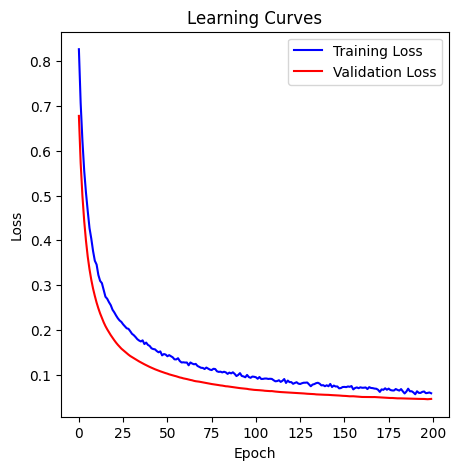

In [35]:
# plotting the learning curves

plt.figure(figsize = (5, 5))
plt.plot(HIST.history['loss'], label = 'Training Loss', color = 'blue')
plt.plot(HIST.history['val_loss'], label = 'Validation Loss', color = 'red')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Learning Curves')
plt.legend()
plt.show()

In [36]:
val_scores = model.predict(x_val).ravel()


125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


In [39]:
print('validation average precision:',
      average_precision_score(y_val, val_scores))


validation average precision: 0.998183395430396
